# 01 · Dataset understanding and exploratory data analysis

**Dataset:** `creditcard.csv` (ULB / Worldline, Kaggle `mlg-ulb/creditcardfraud`, ODbL 1.0 / DbCL 1.0; Dal Pozzolo et al., CIDM 2015). All 284,807 rows are used.

**Purpose:** describe the structure, quality, class balance and distributions of the data before modelling.

**About label use:** some statistics here are split by `Class` (normal vs fraud). They are **descriptive only**. No feature is selected or dropped because of them, and every modelling choice was fixed beforehand in `PROJECT_PLAN.md`.

**About V1–V28:** these are anonymised PCA components. The original features and PCA loadings were never published, so this notebook makes **no claim about what any V feature represents**.

The same results can be produced without the notebook by running `python scripts/run_eda.py`.

In [1]:
import os
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_ROOT = Path("/content/drive/MyDrive/genAI")  # change this if the project folder lives elsewhere on Drive
else:
    PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROJECT_ROOT = PROJECT_ROOT.resolve()
os.environ.setdefault("MPLCONFIGDIR", str(PROJECT_ROOT / ".cache" / "matplotlib"))
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
print("Project root:", PROJECT_ROOT.name)

Project root: genAI


In [2]:
import matplotlib.pyplot as plt
import pandas as pd

from src.data import eda
from src.data.load import load_raw
from src.evaluation import plots
from src.utils.io import load_config, save_json

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
plots.apply_style()

cfg = load_config(PROJECT_ROOT)
FIG_DIR = PROJECT_ROOT / cfg["paths"]["figures_dir"] / "eda"
METRICS_DIR = PROJECT_ROOT / cfg["paths"]["metrics_dir"]

df = load_raw(PROJECT_ROOT, cfg)  # verifies the SHA-256 and the expected schema; the file is only read
print(f"Loaded {len(df):,} rows x {df.shape[1]} columns (SHA-256 verified)")

Loaded 284,807 rows x 31 columns (SHA-256 verified)


In [3]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,-0.551600,-0.617801,-0.991390,-0.311169,1.468177,-0.470401,0.207971,0.025791,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,1.612727,1.065235,0.489095,-0.143772,0.635558,0.463917,-0.114805,-0.183361,-0.145783,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,0.624501,0.066084,0.717293,-0.165946,2.345865,-2.890083,1.109969,-0.121359,-2.261857,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,-0.226487,0.178228,0.507757,-0.287924,-0.631418,-1.059647,-0.684093,1.965775,-1.232622,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,-0.822843,0.538196,1.345852,-1.119670,0.175121,-0.451449,-0.237033,-0.038195,0.803487,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## 1. Structure and descriptive statistics

In [4]:
overview = eda.dataset_overview(df)
print(f"Rows: {overview['rows']:,} | Columns: {overview['columns']} | Memory: {overview['memory_mb']} MB")
pd.Series(overview["dtypes"]).value_counts().rename("number of columns").to_frame()

Rows: 284,807 | Columns: 31 | Memory: 70.63 MB


,number of columns
float64,30
int64,1


In [5]:
eda.feature_summary(df).round(3)

,count,mean,std,min,0.1%,1%,25%,50%,75%,99%,99.9%,max,skew,excess_kurtosis,n_unique
Time,284807.0,94813.86,47488.146,0.000,204.000,2422.000,54201.500,84692.000,139320.500,170560.940,172522.194,172792.000,-0.036,-1.294,124592
V1,284807.0,0.00,1.959,-56.408,-16.044,-6.563,-0.920,0.018,1.316,2.237,2.345,2.455,-3.281,32.487,275663
V2,284807.0,0.00,1.651,-72.716,-15.126,-4.960,-0.599,0.065,0.804,3.802,7.852,22.058,-4.625,95.773,275663
V3,284807.0,-0.00,1.516,-48.326,-9.870,-3.978,-0.890,0.180,1.027,2.728,3.387,9.383,-2.240,26.620,275663
V4,284807.0,0.00,1.416,-5.683,-4.163,-3.123,-0.849,-0.020,0.743,4.248,6.236,16.875,0.676,2.635,275663
V5,284807.0,0.00,1.380,-113.743,-9.409,-3.060,-0.692,-0.054,0.612,3.425,8.075,34.802,-2.426,206.905,275663
V6,284807.0,0.00,1.332,-26.161,-5.290,-2.124,-0.768,-0.274,0.399,4.200,6.165,73.302,1.827,42.642,275663
V7,284807.0,-0.00,1.237,-43.557,-9.365,-3.013,-0.554,0.040,0.570,2.696,7.973,120.589,2.554,405.607,275663
V8,284807.0,0.00,1.194,-73.217,-13.102,-4.034,-0.209,0.022,0.327,2.076,6.135,20.007,-8.522,220.587,275663
V9,284807.0,-0.00,1.099,-13.434,-3.305,-2.455,-0.643,-0.051,0.597,2.987,5.961,15.595,0.555,3.731,275663


## 2. Class balance

In [6]:
balance = eda.class_balance(df)
pd.Series({
    "Normal transactions": f"{balance['normal']:,}",
    "Fraudulent transactions": f"{balance['fraud']:,}",
    "Total": f"{balance['total']:,}",
    "Fraud percentage": f"{balance['fraud_pct']:.4f}%",
    "Normal transactions per fraud": f"{balance['normal_per_fraud']:.1f}",
}).to_frame("value")

,value
Normal transactions,"284,315"
Fraudulent transactions,492
Total,"284,807"
Fraud percentage,0.1727%
Normal transactions per fraud,577.9


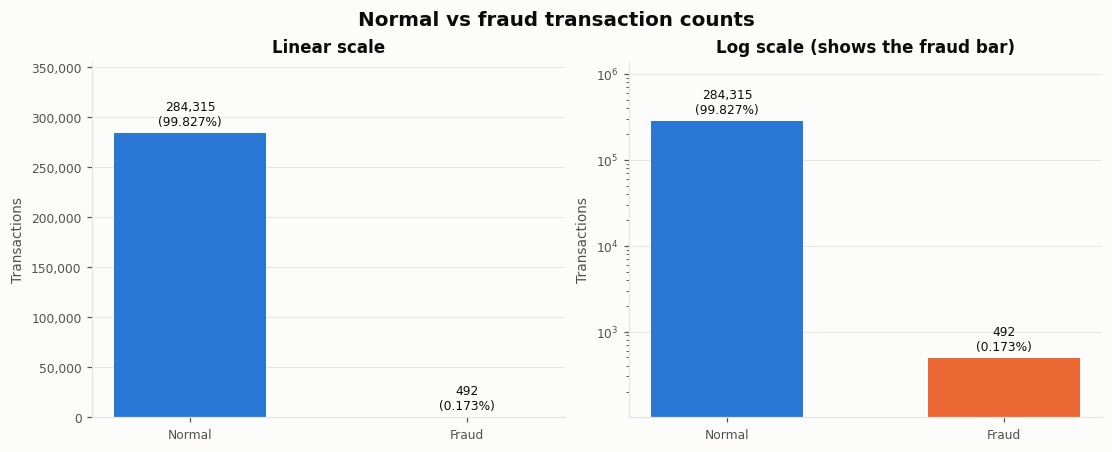

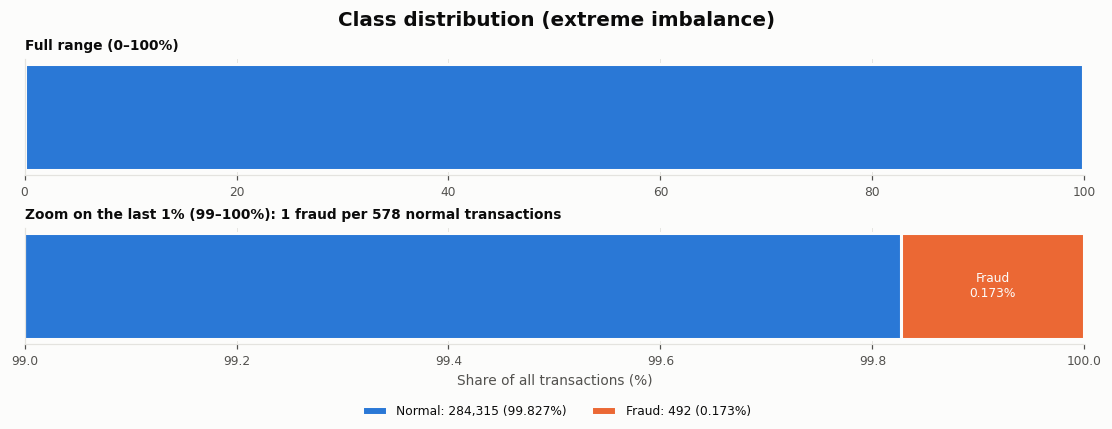

In [7]:
plots.plot_class_counts(df, FIG_DIR / "01_class_counts.png")
plt.show()
plots.plot_class_share(df, FIG_DIR / "02_class_distribution.png")
plt.show()

## 3. Data quality: missing, duplicate, invalid and unexpected values

In [8]:
quality = eda.quality_report(df)
pd.Series({
    "Missing values (all columns)": quality["missing_total"],
    "Infinite values": quality["infinite_total"],
    "Non-numeric columns": quality["non_numeric_columns"] or "none",
    "Class values": quality["class_values"],
    "Exact duplicate rows": quality["exact_duplicate_rows"],
    "  ...of which normal / fraud": f"{quality['exact_duplicate_rows_by_class'].get(0, 0)} / {quality['exact_duplicate_rows_by_class'].get(1, 0)}",
    "Rows repeating a feature vector (ignoring Time)": quality["rows_repeating_a_vector_ignoring_time"],
    "Distinct V1-V28 + Amount vectors": quality["distinct_input_vectors"],
    "Largest number of copies of one vector": quality["max_copies_of_one_vector"],
    "Vectors carrying both labels": quality["vectors_with_conflicting_labels"],
    "Constant columns": quality["constant_columns"] or "none",
    "Near-constant columns (>99% one value)": quality["near_constant_columns_gt_99pct"] or "none",
    "Negative amounts": quality["negative_amounts"],
    "Zero amounts (normal / fraud)": f"{quality['zero_amounts']} ({quality['zero_amounts_by_class'].get(0, 0)} / {quality['zero_amounts_by_class'].get(1, 0)})",
    "Negative Time values": quality["negative_time"],
    "Time sorted ascending": quality["time_is_sorted"],
}).to_frame("result")

,result
Missing values (all columns),0
Infinite values,0
Non-numeric columns,none
Class values,"[0, 1]"
Exact duplicate rows,1081
...of which normal / fraud,1062 / 19
Rows repeating a feature vector (ignoring Time),9144
Distinct V1-V28 + Amount vectors,275663
Largest number of copies of one vector,77
Vectors carrying both labels,0


No values are missing, infinite or of an unexpected type. The data is **not** fully modelling-ready, though:
- **Duplicates:** 1,081 rows are exact duplicates, and 9,144 rows repeat an earlier feature vector at a different time. These rows are **kept**, and the split in notebook 02 keeps every copy of a vector in the same partition, so duplicates cannot leak between train and test.
- **Scaling:** `Amount` and `Time` are on raw scales, and the V features have unequal variances (sections 4–6).

## 4. Transaction amount

In [9]:
amount = eda.amount_summary(df)
print(f"Skewness: raw {amount['skew_raw']:.2f} -> log1p {amount['skew_log1p']:.2f} | excess kurtosis (raw) {amount['excess_kurtosis_raw']:.0f} | max decimals {amount['max_decimal_places']}")
pd.DataFrame(amount["by_class"]).rename(columns={0: "Normal", 1: "Fraud"}).round(2)

Skewness: raw 16.98 -> log1p 0.16 | excess kurtosis (raw) 845 | max decimals 2


,Normal,Fraud
count,284315.00,492.00
mean,88.29,122.21
std,250.11,256.68
min,0.00,0.00
25%,5.65,1.00
50%,22.00,9.25
75%,77.05,105.89
99%,1016.97,1357.43
max,25691.16,2125.87


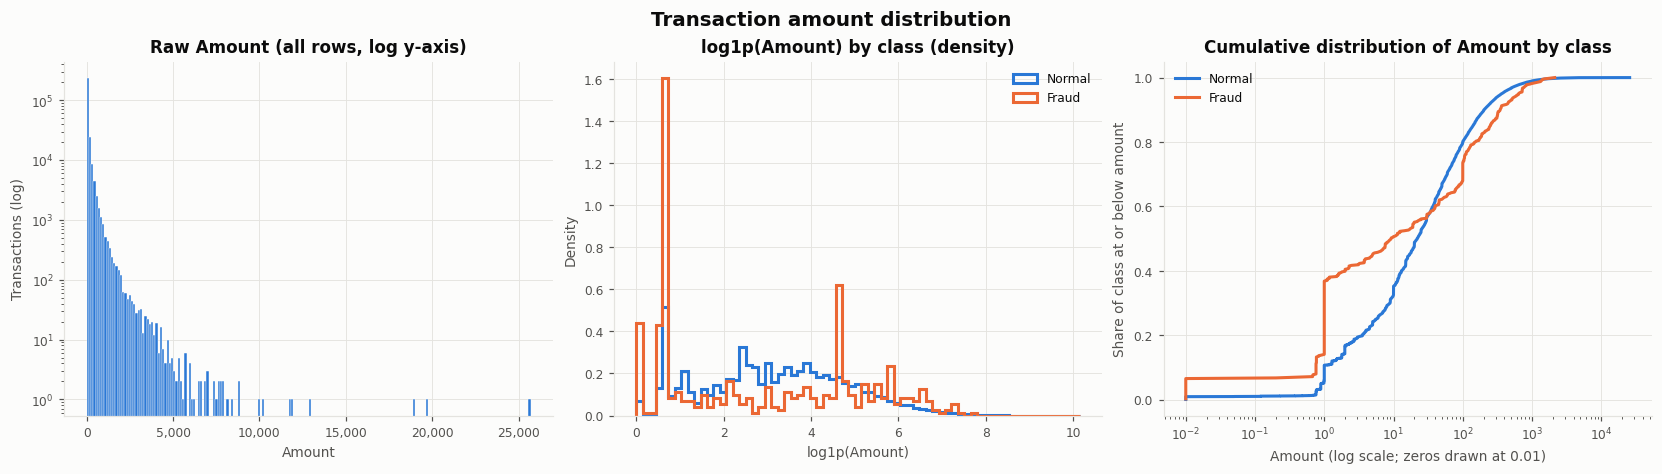

In [10]:
plots.plot_amount_distribution(df, FIG_DIR / "03_amount_distribution.png")
plt.show()

## 5. Transaction time

In [11]:
time_stats = eda.time_summary(df)
print(f"Time spans {time_stats['min_seconds']:.0f}-{time_stats['max_seconds']:.0f} s ({time_stats['span_hours']:.1f} h); sorted: {time_stats['is_sorted']}")
display(pd.DataFrame(time_stats["per_day"]).T.round(3))
per_hour = pd.DataFrame(time_stats["per_hour_of_cycle"]).T
per_hour.index.name = "hour of 24-h cycle (0 = first hour in file)"
per_hour.round(3).T

Time spans 0-172792 s (48.0 h); sorted: True


,normal,fraud,fraud_rate_pct
day_1,144505.0,281.0,0.194
day_2,139810.0,211.0,0.151


hour of 24-h cycle (0 = first hour in file),0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
normal,7689.000,4210.000,3271.000,3475.000,2186.000,2979.000,4092.000,7220.000,10267.000,15822.000,16590.000,16803.000,15403.00,15348.000,16547.000,16435.000,16431.000,16137.000,17006.000,15630.000,16738.000,17687.00,15432.000,10917.000
fraud,6.000,10.000,57.000,17.000,23.000,11.000,9.000,23.000,9.000,16.000,8.000,53.000,17.00,17.000,23.000,26.000,22.000,29.000,33.000,19.000,18.000,16.00,9.000,21.000
fraud_rate_pct,0.078,0.237,1.713,0.487,1.041,0.368,0.219,0.318,0.088,0.101,0.048,0.314,0.11,0.111,0.139,0.158,0.134,0.179,0.194,0.121,0.107,0.09,0.058,0.192


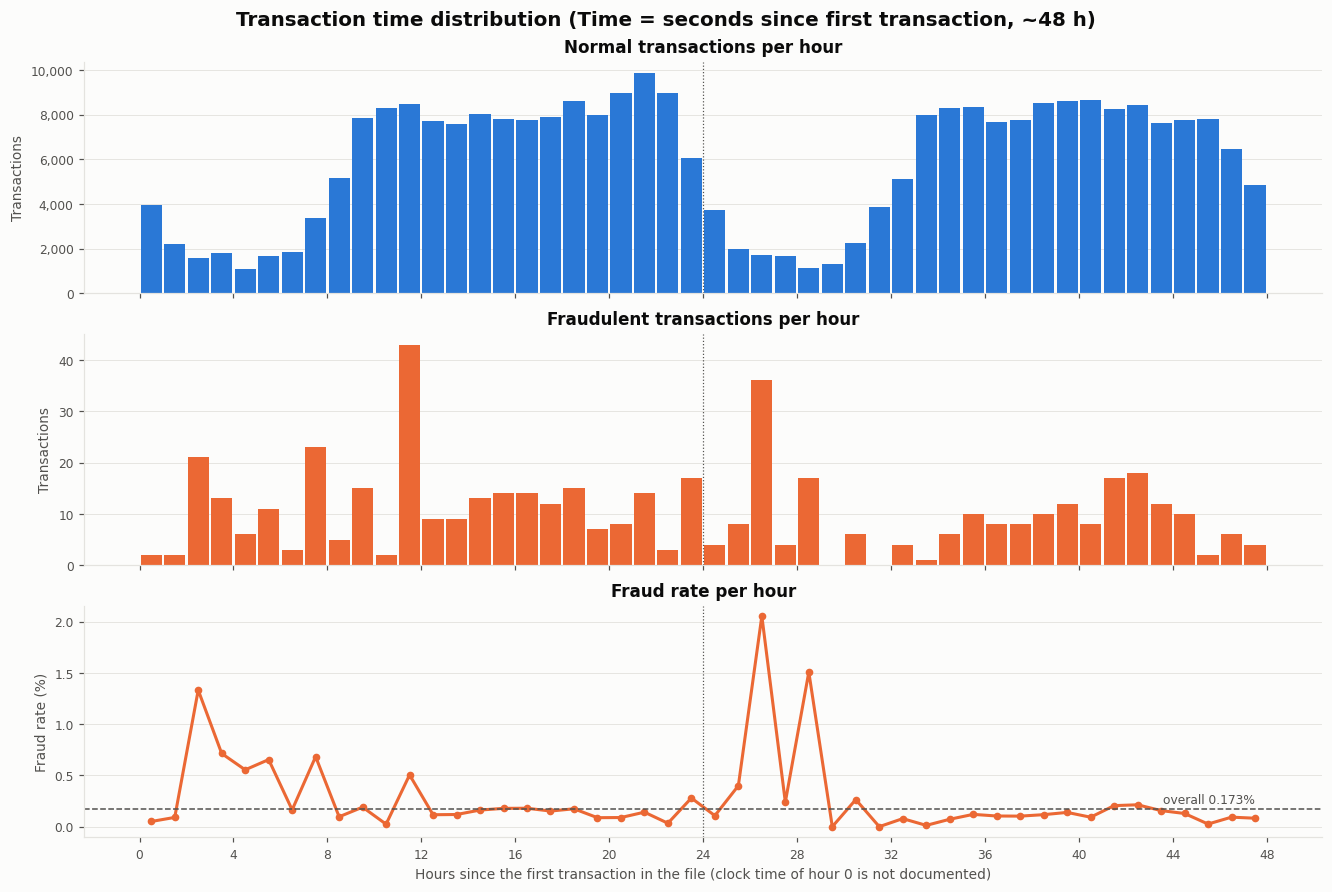

In [12]:
plots.plot_time_distribution(df, FIG_DIR / "04_time_distribution.png")
plt.show()

## 6. Distributions of V1–V28

In [13]:
pca = eda.pca_feature_checks(df)
pd.Series({
    "Largest |mean| of any V feature": f"{pca['max_abs_mean']:.1e}",
    "Std range": f"{pca['std_min']:.3f} - {pca['std_max']:.3f} (ratio {pca['std_ratio_max_over_min']:.1f}x)",
    "Std strictly decreasing V1 -> V28": pca["std_strictly_decreasing"],
    "Skewness range": f"{pca['skew_range'][0]:.2f} to {pca['skew_range'][1]:.2f}",
    "Excess kurtosis range": f"{pca['excess_kurtosis_range'][0]:.2f} to {pca['excess_kurtosis_range'][1]:.1f}",
}).to_frame("value")

,value
Largest |mean| of any V feature,4.9e-15
Std range,0.330 - 1.959 (ratio 5.9x)
Std strictly decreasing V1 -> V28,True
Skewness range,-8.52 to 11.19
Excess kurtosis range,0.20 to 933.4


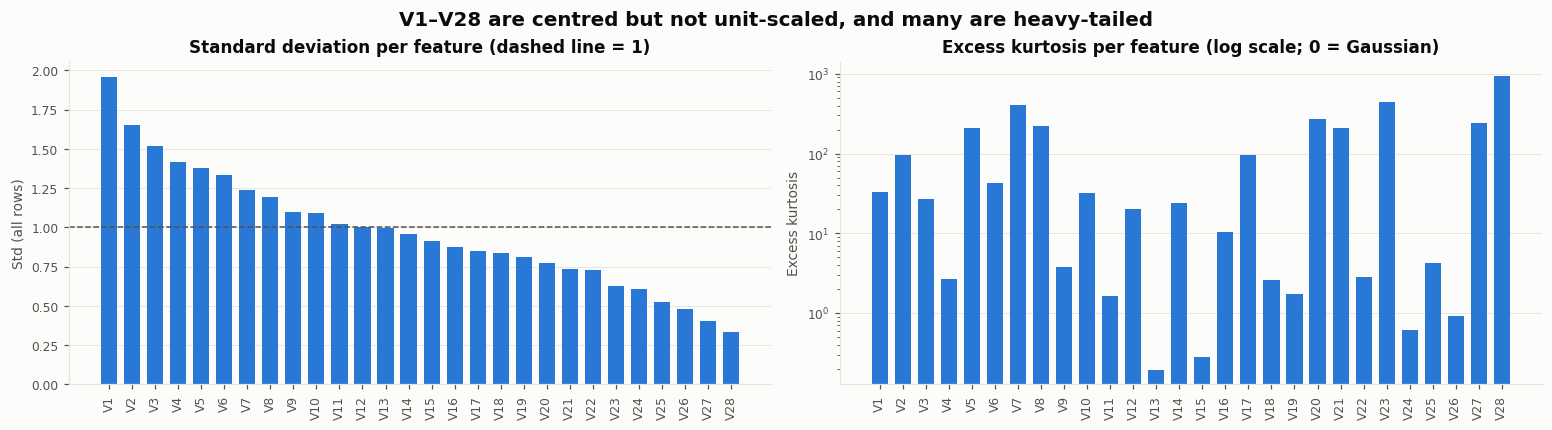

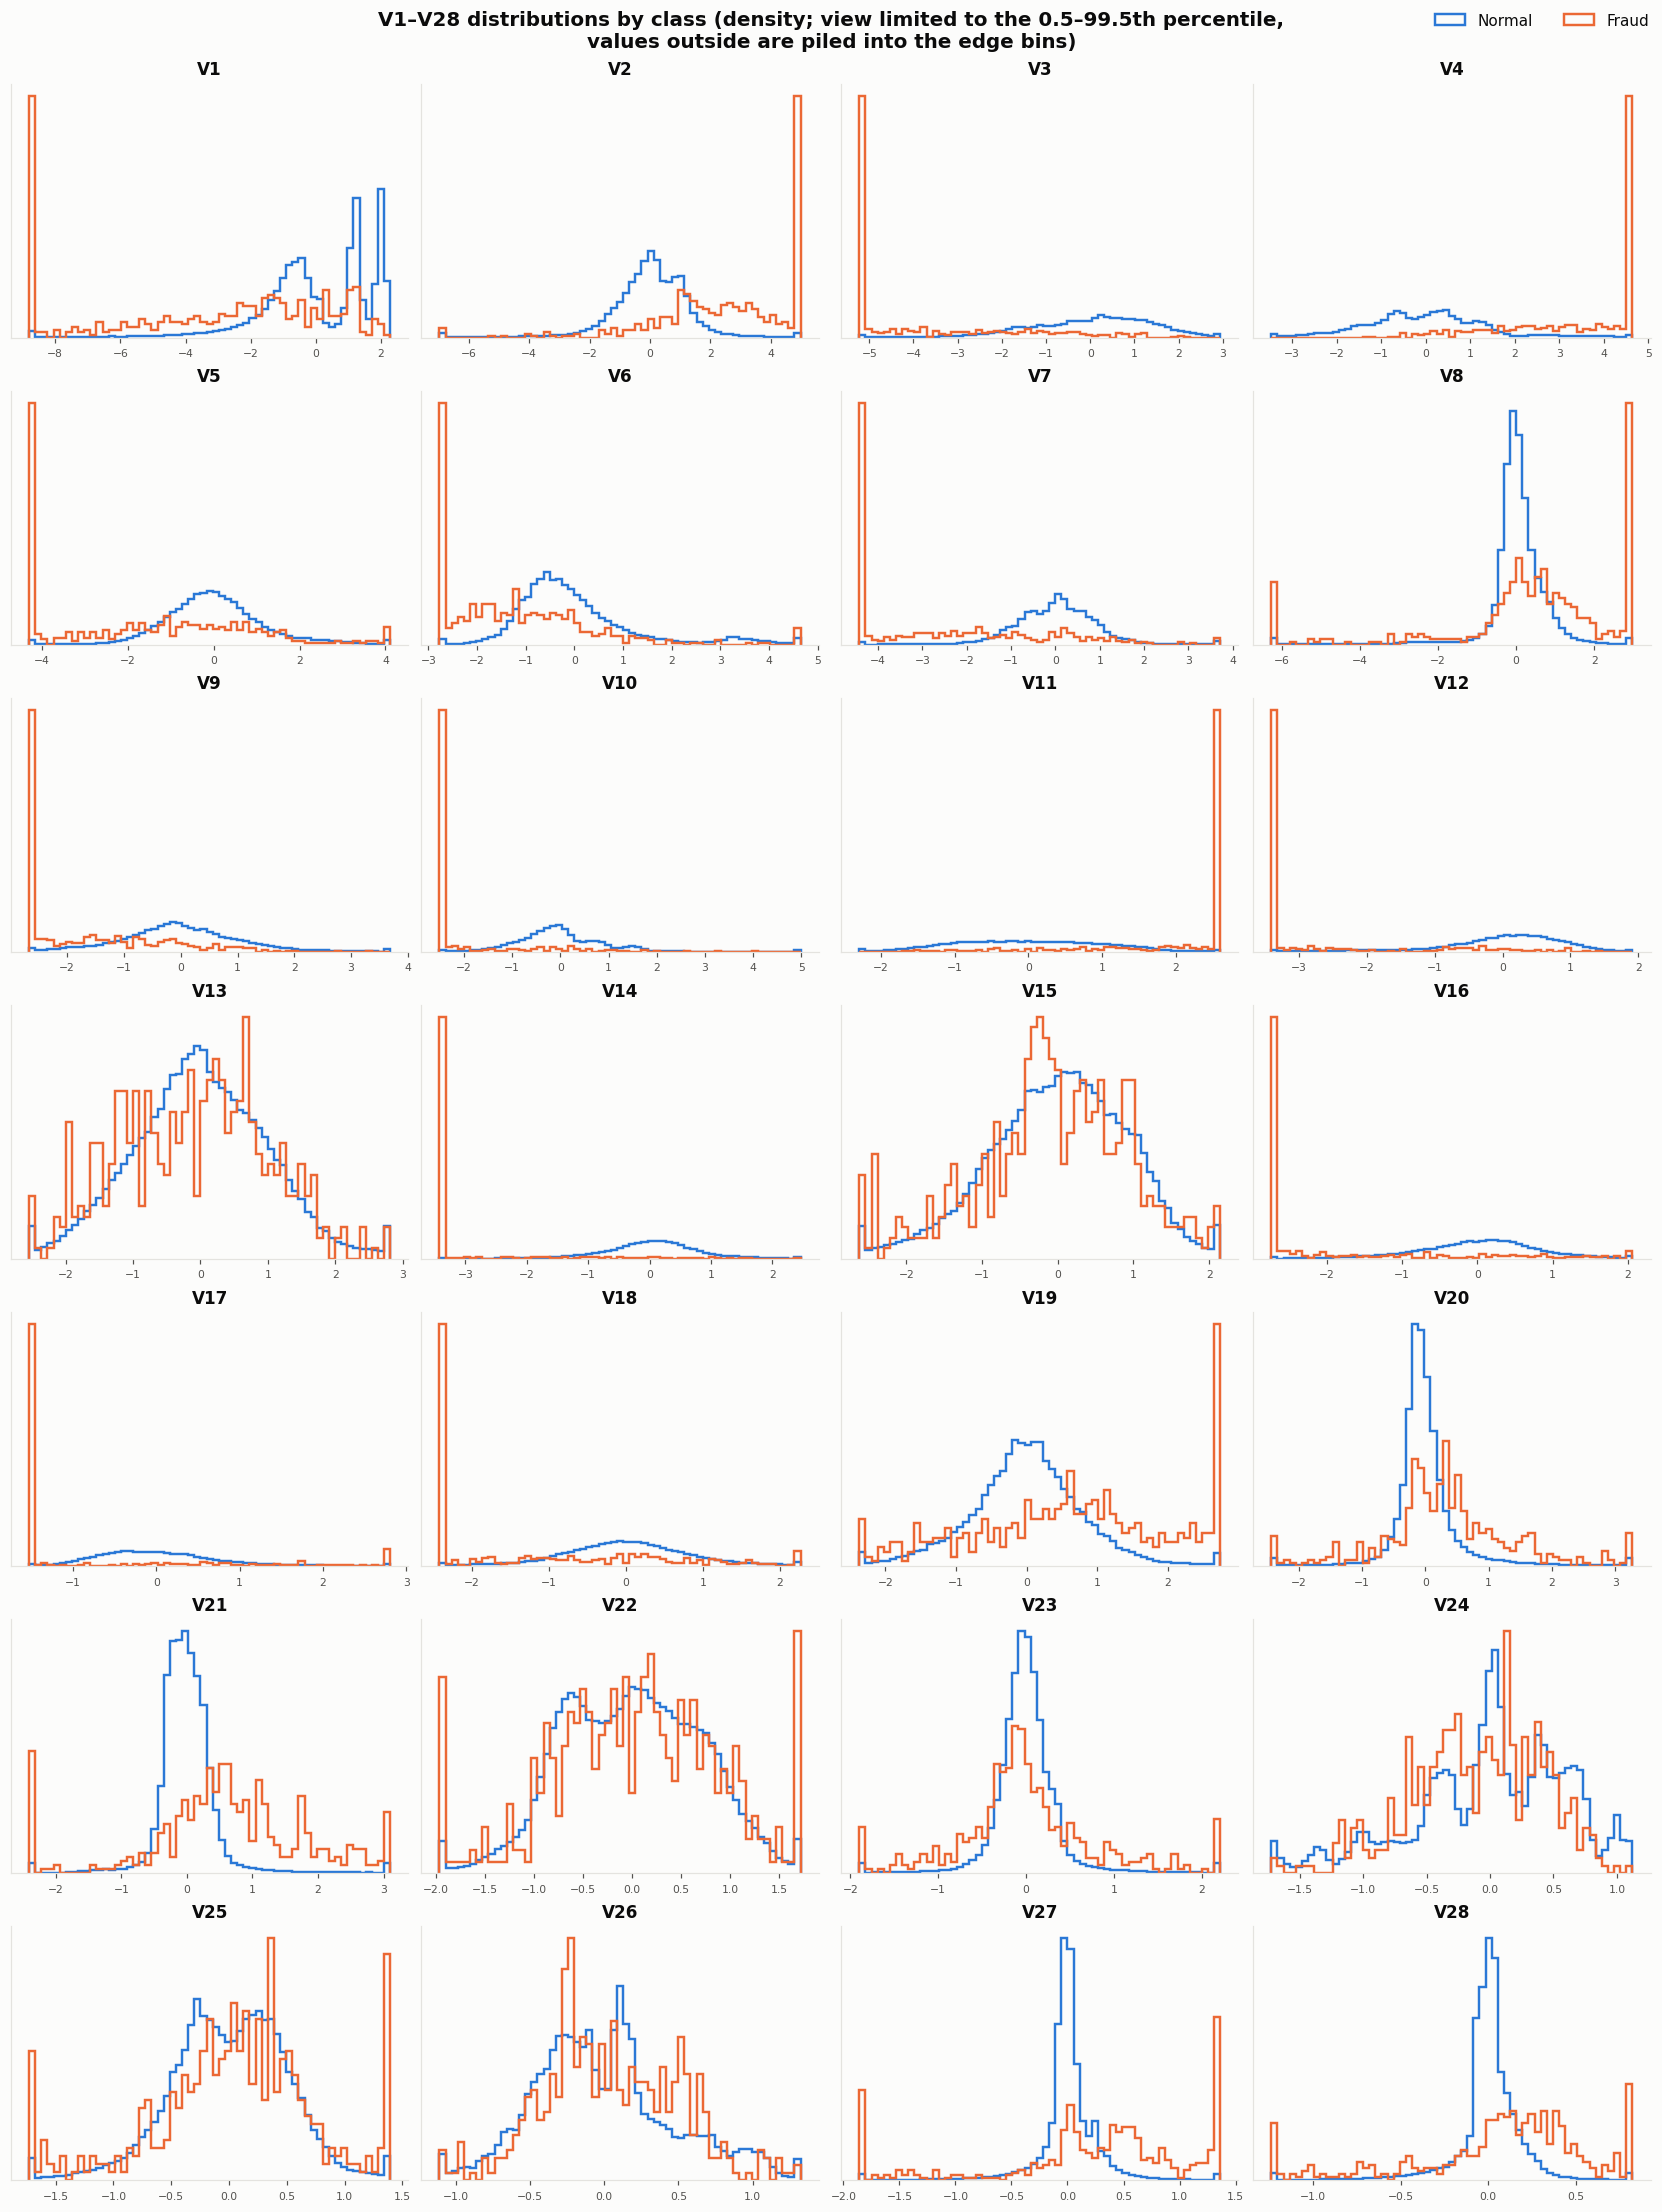

In [14]:
plots.plot_feature_scales(df, FIG_DIR / "05_feature_scales.png")
plt.show()
plots.plot_feature_grid(df, FIG_DIR / "06_feature_distributions_all.png")
plt.show()

## 7. Correlation structure

Max |off-diagonal correlation| among V1-V28: all rows 2.3e-14, normal rows 0.169, fraud rows 0.971
Strongest |correlation| of Amount with V features: {'V2': 0.5314, 'V7': 0.3973, 'V5': 0.3864, 'V20': 0.3394, 'V1': 0.2277}


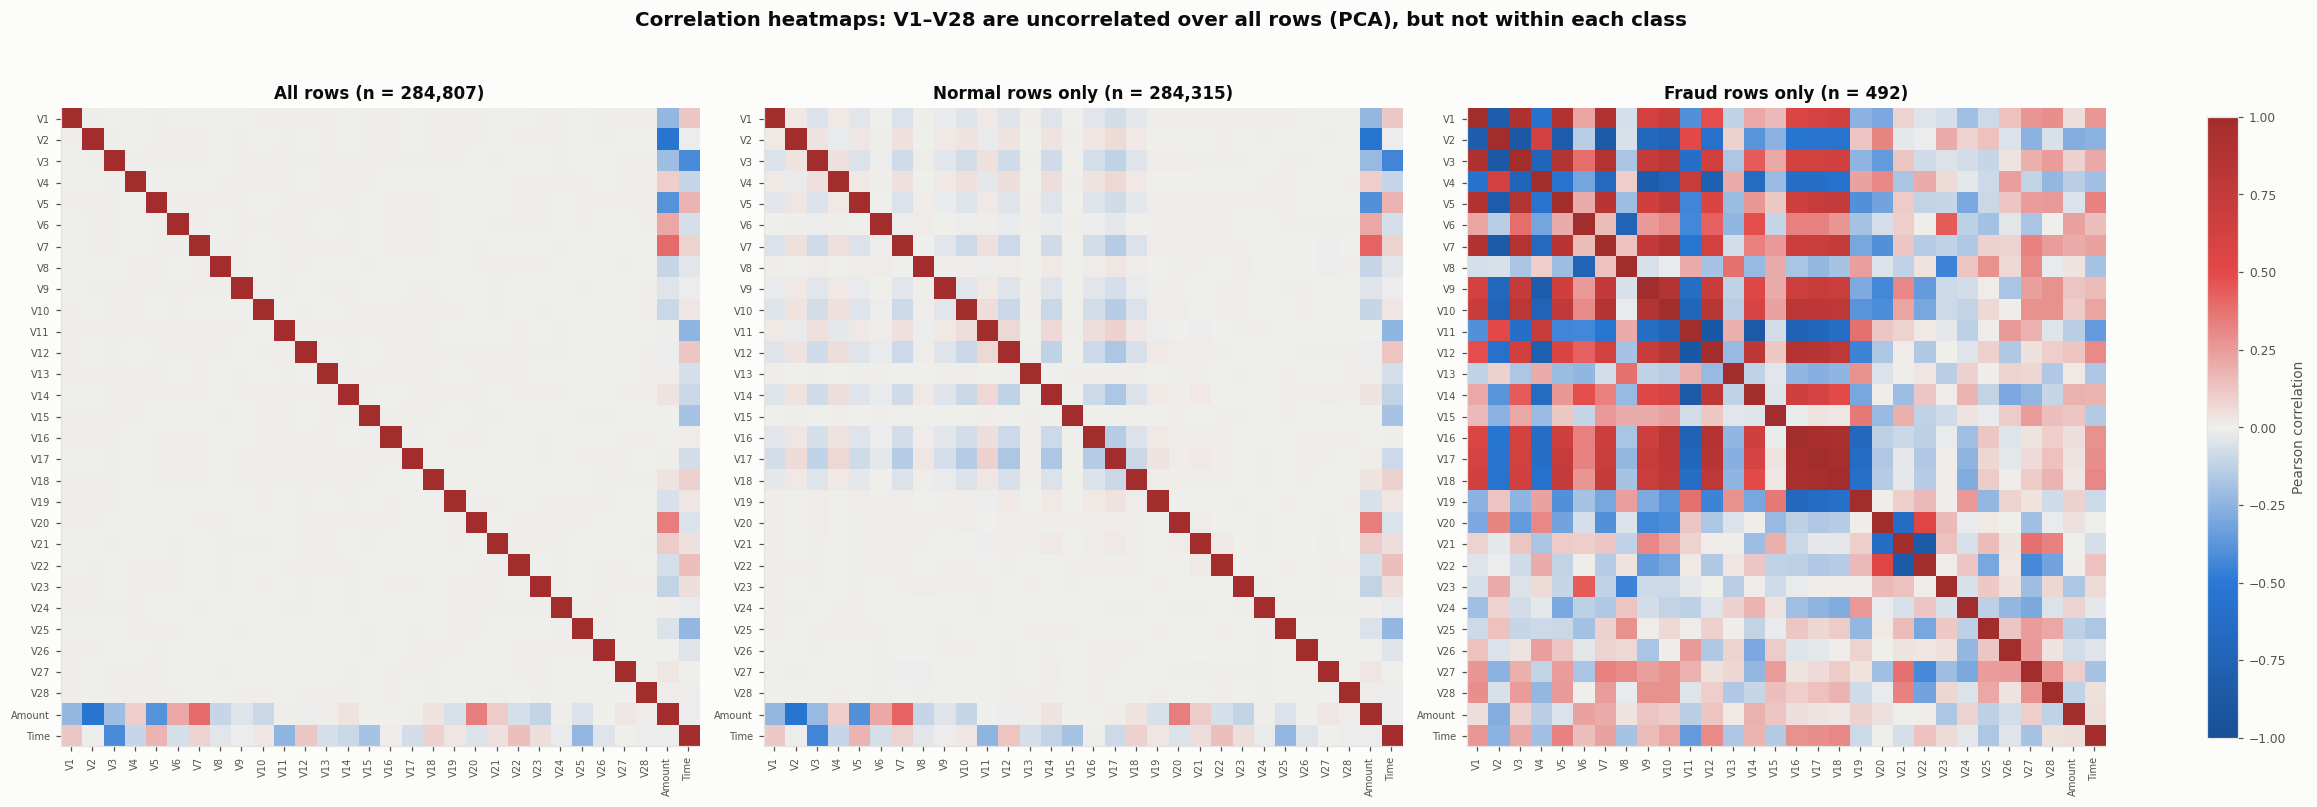

In [15]:
print(f"Max |off-diagonal correlation| among V1-V28: all rows {pca['max_abs_offdiag_corr_all_rows']:.1e}, "
      f"normal rows {pca['max_abs_offdiag_corr_normal_rows']:.3f}, fraud rows {pca['max_abs_offdiag_corr_fraud_rows']:.3f}")
print("Strongest |correlation| of Amount with V features:", pca["amount_corr_with_V_top"])
plots.plot_correlation_heatmaps(df, FIG_DIR / "08_correlation_heatmaps.png")
plt.show()

## 8. Normal vs fraudulent feature comparison (descriptive)

In [16]:
comparison = eda.class_comparison(df)
comparison[["mean_normal", "mean_fraud", "median_normal", "median_fraud", "smd"]].head(10).round(3)

,mean_normal,mean_fraud,median_normal,median_fraud,smd
V17,0.012,-6.666,-0.065,-5.303,-8.910
V14,0.012,-6.972,0.052,-6.730,-7.786
V12,0.011,-6.259,0.142,-5.503,-6.629
V10,0.010,-5.677,-0.092,-4.579,-5.446
V16,0.007,-4.140,0.067,-3.550,-4.909
V3,0.012,-7.033,0.182,-5.075,-4.828
V7,0.010,-5.569,0.041,-3.034,-4.732
V11,-0.007,3.800,-0.035,3.586,3.795
V4,-0.008,4.542,-0.022,4.177,3.251
V18,0.004,-2.246,-0.003,-1.664,-2.728


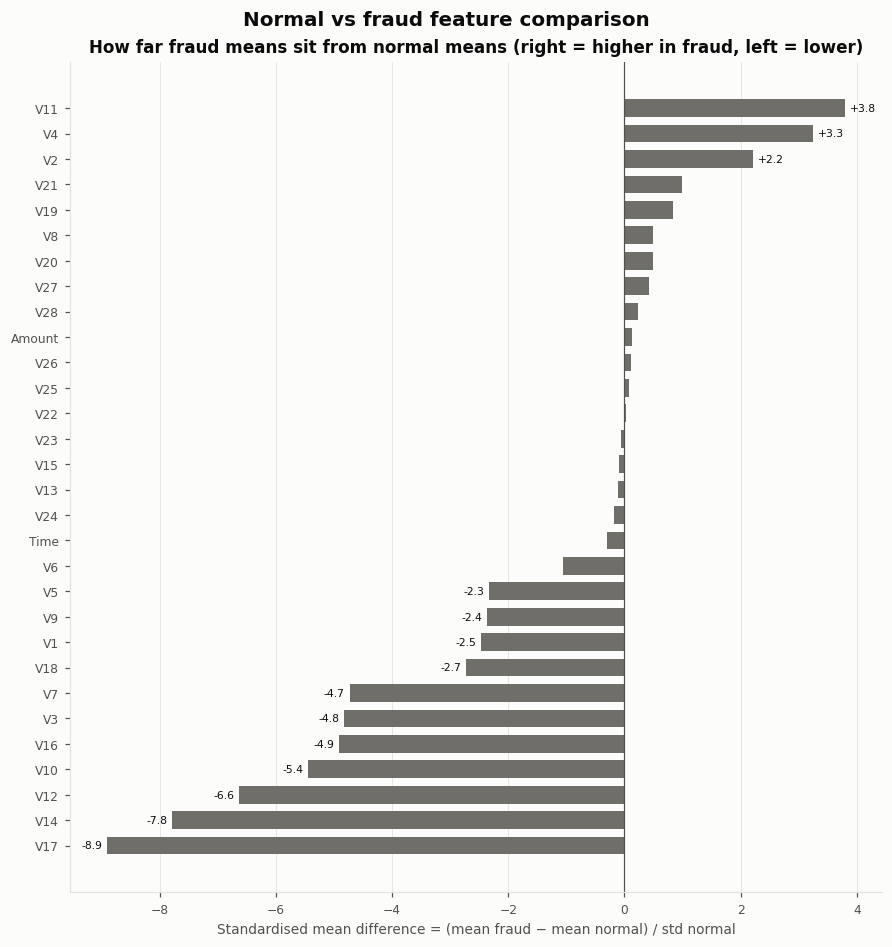

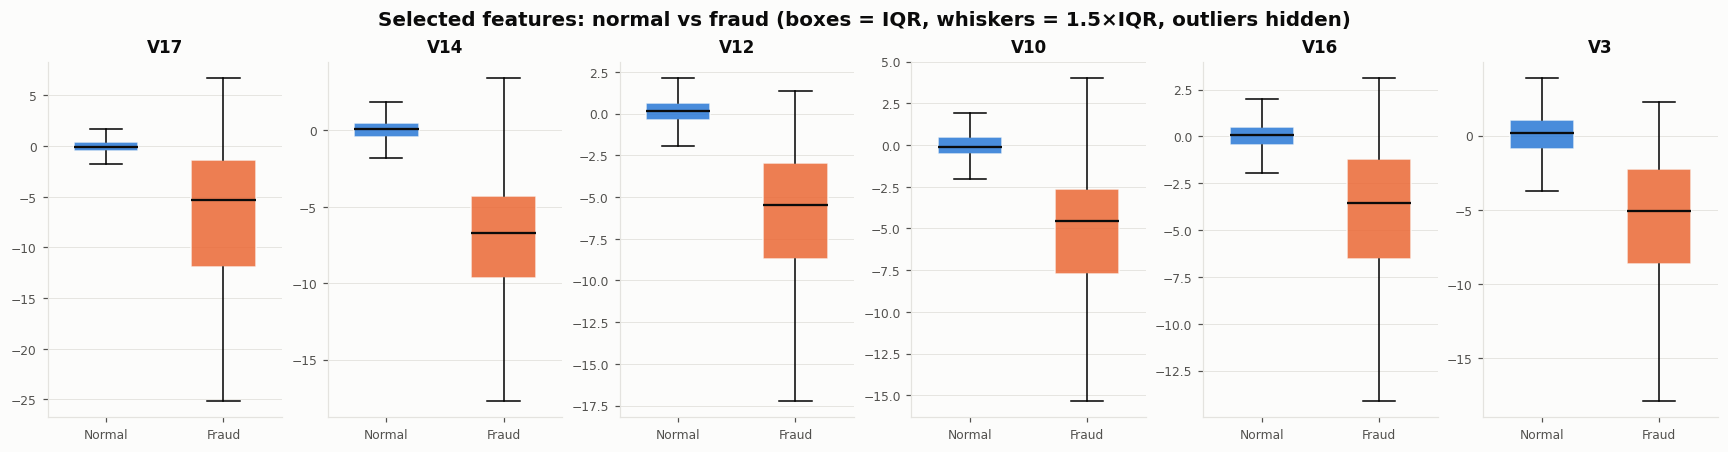

Rows with any V feature beyond |z| > 5: 7,952 (7,545 normal, 407 fraud = 82.7% of all frauds)


In [17]:
plots.plot_class_comparison(comparison, FIG_DIR / "09_normal_vs_fraud_comparison.png")
plt.show()
SELECTED = comparison.index[:6].tolist()  # largest |SMD|, chosen only to illustrate the separation
plots.plot_selected_features(df, SELECTED, FIG_DIR / "07_selected_features.png")
plt.show()
extreme = eda.extreme_value_report(df)
print(f"Rows with any V feature beyond |z| > 5: {extreme['rows_with_any_extreme_feature']:,} "
      f"({extreme['normal_rows']:,} normal, {extreme['fraud_rows']} fraud = {extreme['share_of_frauds_pct']:.1f}% of all frauds)")

## 9. Save statistics

In [18]:
stats = eda.compute_eda_stats(df)
save_json(stats, METRICS_DIR / "eda_stats.json")
eda.feature_summary(df).to_csv(METRICS_DIR / "eda_feature_summary.csv")
comparison.to_csv(METRICS_DIR / "eda_class_comparison.csv")
print("Saved:", sorted(p.name for p in METRICS_DIR.glob("eda_*")))
print("Figures:", sorted(p.name for p in FIG_DIR.glob("*.png")))

Saved: ['eda_class_comparison.csv', 'eda_feature_summary.csv', 'eda_stats.json']
Figures: ['01_class_counts.png', '02_class_distribution.png', '03_amount_distribution.png', '04_time_distribution.png', '05_feature_scales.png', '06_feature_distributions_all.png', '07_selected_features.png', '08_correlation_heatmaps.png', '09_normal_vs_fraud_comparison.png']


## 10. Interpretation of key findings

1. **Size and balance.** 284,807 transactions: 284,315 normal and 492 fraud (**0.1727%**, about 1 fraud per 578 normal transactions). This extreme imbalance makes accuracy meaningless. Average precision (PR-AUC) is the primary metric, and precision depends on prevalence, so evaluation sets must keep the natural fraud rate.
2. **Quality.** No missing, infinite or non-numeric values; `Class` holds only 0/1; no constant features. There are 1,081 exact duplicate rows (1,062 normal, 19 fraud) and 9,144 rows that repeat a feature vector at a different time. No vector carries both labels. Duplicates are kept and handled by a group-aware split (notebook 02).
3. **Amount.** Strongly right-skewed (skew 16.98, max 25,691.16, median 22.00). After `log1p` the skew is 0.16, so `log1p(Amount)` followed by standardisation is used as a model input. Fraud amounts have a lower median (9.25 vs 22.00) and a larger share of very small values (25th percentile 1.00 vs 5.65). 1,825 transactions have `Amount = 0` (27 of them fraud).
4. **Time.** `Time` counts seconds from the first transaction and covers about 48 hours. Volume follows a clear daily cycle with a low-volume period in hours 1–7 of each cycle (e.g. 2,209 transactions in hour 4 vs about 16,500 in busy hours). The fraud rate is highest in that period (1.71% in hour 2, 1.04% in hour 4). The real clock time of hour 0 is not documented. Raw `Time` behaves like a row counter, so it is **excluded from model inputs**. A cyclical hour feature is a planned sensitivity analysis only.
5. **V1–V28 scale and shape.** The V features are centred (|mean| < 1e-14) and uncorrelated across all rows, as expected from PCA. Their standard deviations fall steadily from 1.96 (V1) to 0.33 (V28), so they are **not on a common scale** and need standardising. Many are heavy-tailed (excess kurtosis up to 933 for V28; skew from −8.5 to 11.2). The loss and training must therefore cope with extreme values; for example, gradient clipping is part of the plan.
6. **Correlation.** Over all rows the V features are orthogonal by construction, but within a class they are not: up to |r| = 0.17 among normal rows and up to |r| = 0.97 among fraud rows. `Amount` correlates with several components (|r| = 0.53 with V2, 0.40 with V7, 0.39 with V5). These dependencies are structure a generative model should reproduce.
7. **Normal vs fraud.** Fraud rows sit far from normal rows on several components. Standardised mean differences are −8.9 (V17), −7.8 (V14), −6.6 (V12), −5.4 (V10), and +3.8 (V11). 82.7% of frauds have at least one V feature beyond |z| = 5, against 2.7% of normal rows. This is the signal a reconstruction-based detector trained on normal data can exploit. It is a descriptive observation, not a claim about what these components mean, and it is not used to select features.